In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pymc as pm
import arviz as az
import ICIW_Plots
from scipy.integrate import odeint
from HSA_Cam_A_003 import (
    Chem,
    bmodel,
    plot_true_data,
    plot_observed_data,
    plot_inference,
    plot_model_trace,
)

In [2]:
plt.style.use("ICIWstyle")

c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\ICIW_Plots\layout.py:241: UserWarning: Unscientific behavior. No xlabel provided.
  warnings.warn("Unscientific behavior. No xlabel provided.")
c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\ICIW_Plots\layout.py:276: UserWarning: Unscientific behavior. No ylabel provided.
  warnings.warn("Unscientific behavior. No ylabel provided.")
c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.canvas.print_figure(bytes_io, **kw)


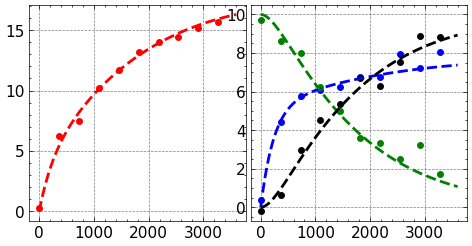

In [3]:
# Times for observation
times = np.linspace(0, 1 * 60 * 60, 100)

y0_true = (0, 0, 10, 0)
theta_true = (10e5, 300, 3e-3, 0.0001)
# sigma = 0
sigma = 0.5

y_true = odeint(Chem.reaction, t=times, y0=y0_true, args=(theta_true,))
y_true[:, 0] *= 1000  # convert m3 to L H2 used (up to a constant atleast)
# Add noise
t_obs = times[::10]
y_obs = np.random.normal(y_true, sigma)[::10, :]  # downsample and add noise

## Plotting the base model
fig = ICIW_Plots.figure(layout="double_column")
axs = ICIW_Plots.make_square_subplots(
    fig, ax_width=5.5 * ICIW_Plots.cm2inch, ax_layout=(1, 2)
)
plot_true_data(axs, times, y_true)
plot_observed_data(axs, t_obs, y_obs)
plt.show()

In [4]:
model = bmodel(t_obs, y_obs)
with model:
    prior_idata = pm.sample_prior_predictive(samples=1000, random_seed=23489)

c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\pytensor\link\c\cmodule.py:2968: UserWarning: PyTensor could not link to a BLAS installation. Operations that might benefit from BLAS will be severely degraded.
This usually happens when PyTensor is installed via pip. We recommend it be installed via conda/mamba/pixi instead.
Alternatively, you can use an experimental backend such as Numba or JAX that perform their own BLAS optimizations, by setting `pytensor.config.mode == 'NUMBA'` or passing `mode='NUMBA'` when compiling a PyTensor function.
For more options and details see https://pytensor.readthedocs.io/en/latest/troubleshooting.html#how-do-i-configure-test-my-blas-library
  warnings.warn(
Sampling: [LH2, k, kla, sigma]


c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\ICIW_Plots\layout.py:241: UserWarning: Unscientific behavior. No xlabel provided.
  warnings.warn("Unscientific behavior. No xlabel provided.")
c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\ICIW_Plots\layout.py:276: UserWarning: Unscientific behavior. No ylabel provided.
  warnings.warn("Unscientific behavior. No ylabel provided.")
c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\IPython\core\events.py:82: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  func(*args, **kwargs)


Plotting sample 1/25
Plotting sample 2/25
Plotting sample 3/25
Plotting sample 4/25
Plotting sample 5/25
Plotting sample 6/25
Plotting sample 7/25
Plotting sample 8/25
Plotting sample 9/25
Plotting sample 10/25
Plotting sample 11/25
Plotting sample 12/25
Plotting sample 13/25
Plotting sample 14/25
Plotting sample 15/25
Plotting sample 16/25
Plotting sample 17/25
Plotting sample 18/25
Plotting sample 19/25
Plotting sample 20/25
Plotting sample 21/25
Plotting sample 22/25
Plotting sample 23/25
Plotting sample 24/25
Plotting sample 25/25


c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.canvas.print_figure(bytes_io, **kw)


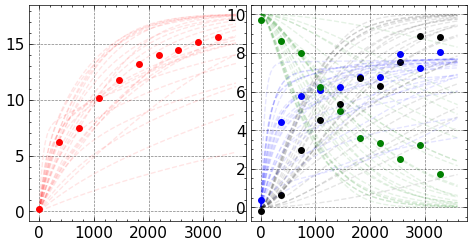

In [5]:
fig = ICIW_Plots.figure(layout="double_column")
axs = ICIW_Plots.make_square_subplots(
    fig, ax_width=5.5 * ICIW_Plots.cm2inch, ax_layout=(1, 2)
)
plot_observed_data(axs, t_obs, y_obs)
plot_inference(
    axs,
    prior_idata,
    times=times,
    num_samples=25,
    lw=1,
    alpha=0.1,
)

In [6]:
import arviz as az

prior_data = az.extract(
    prior_idata, group="prior", num_samples=25, var_names=["kla", "k", "sigma"]
)
display(prior_data)
# get the data array from the xarray dataset

prior_data.isel(sample=0)[["kla", "k", "sigma"]].to_array().values

<xarray.Dataset> Size: 1kB
Dimensions:  (sample: 25)
Coordinates:
  * sample   (sample) object 200B MultiIndex
  * chain    (sample) int64 200B 0 0 0 0 0 0 0 0 0 0 0 ... 0 0 0 0 0 0 0 0 0 0 0
  * draw     (sample) int64 200B 643 717 710 804 63 935 ... 148 80 691 108 704
Data variables:
    kla      (sample) float64 200B 0.002135 0.001241 ... 0.009457 0.003076
    k        (sample) float64 200B 0.0001811 4.445e-05 ... 8.849e-05 2.083e-05
    sigma    (sample) float64 200B 1.292 0.6525 0.09177 ... 0.8151 0.142 1.05
Attributes:
    created_at:                 2025-09-26T10:55:31.333213+00:00
    arviz_version:              0.22.0
    inference_library:          pymc
    inference_library_version:  5.25.1

array([2.13480738e-03, 1.81080211e-04, 1.29227552e+00])

In [7]:
with model:
    posterior_idata = pm.sample(
        draws=1000,
        tune=500,
        target_accept=0.9,
        random_seed=23489,
        return_inferencedata=True,
    )

c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\threadpoolctl.py:1226: RuntimeWarning: 
Found Intel OpenMP ('libiomp') and LLVM OpenMP ('libomp') loaded at
the same time. Both libraries are known to be incompatible and this
can cause random crashes or deadlocks on Linux when loaded in the
same Python program.
Using threadpoolctl may cause crashes or deadlocks. For more
information and possible workarounds, please see
    https://github.com/joblib/threadpoolctl/blob/master/multiple_openmp.md

  warnings.warn(msg, RuntimeWarning)
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [kla, k, sigma]


Output()

Sampling 4 chains for 500 tune and 1_000 draw iterations (2_000 + 4_000 draws total) took 708 seconds.


c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\ICIW_Plots\layout.py:241: UserWarning: Unscientific behavior. No xlabel provided.
  warnings.warn("Unscientific behavior. No xlabel provided.")
c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\ICIW_Plots\layout.py:276: UserWarning: Unscientific behavior. No ylabel provided.
  warnings.warn("Unscientific behavior. No ylabel provided.")
c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.canvas.print_figure(bytes_io, **kw)


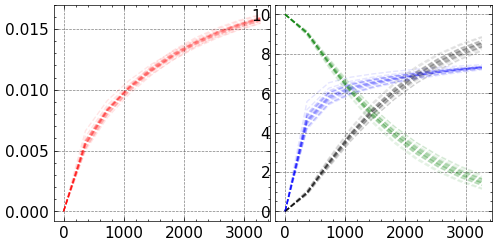

In [8]:
post_data = az.extract(
    posterior_idata,
    group="posterior",
    num_samples=25,
    var_names=["y_hat"],
)
# display(post_data)

fig = ICIW_Plots.figure(layout="double_column")
axs = ICIW_Plots.make_square_subplots(
    fig, ax_width=5.5 * ICIW_Plots.cm2inch, ax_layout=(1, 2)
)

for i in range(25):
    # print(f"Plotting sample {i+1}/25")
    plot_true_data(
        axs,
        t_obs,
        post_data.values[:, :, i],
        lw=1,
        alpha=0.1,
    )
plt.show()

c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\ICIW_Plots\layout.py:241: UserWarning: Unscientific behavior. No xlabel provided.
  warnings.warn("Unscientific behavior. No xlabel provided.")
c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\ICIW_Plots\layout.py:276: UserWarning: Unscientific behavior. No ylabel provided.
  warnings.warn("Unscientific behavior. No ylabel provided.")
c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.canvas.print_figure(bytes_io, **kw)


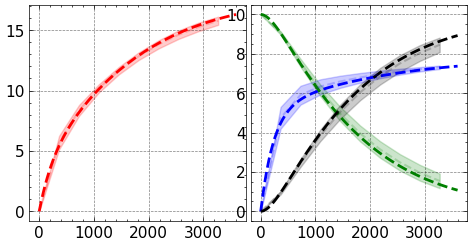

In [9]:
post_data = az.extract(
    posterior_idata,
    group="posterior",
    var_names=["y_hat"],
)
# display(post_data)

post_data[:, 0, :] *= 1000

fig = ICIW_Plots.figure(layout="double_column")
axs = ICIW_Plots.make_square_subplots(
    fig, ax_width=5.5 * ICIW_Plots.cm2inch, ax_layout=(1, 2)
)

plot_true_data(axs, times, y_true, lw=2)

plot_true_data(
    axs,
    t_obs,
    post_data.values.mean(axis=2),
    lw=1.5,
    alpha=0.2,
)

axs[0, 0].fill_between(
    t_obs,
    np.percentile(post_data.values, 5, axis=2)[:, 0],
    np.percentile(post_data.values, 95, axis=2)[:, 0],
    color="red",
    alpha=0.2,
    zorder=0,
)

axs[0, 1].fill_between(
    t_obs,
    np.percentile(post_data.values, 5, axis=2)[:, 1],
    np.percentile(post_data.values, 95, axis=2)[:, 1],
    color=["blue"],
    alpha=0.2,
    zorder=0,
)
axs[0, 1].fill_between(
    t_obs,
    np.percentile(post_data.values, 5, axis=2)[:, 2],
    np.percentile(post_data.values, 95, axis=2)[:, 2],
    color=["green"],
    alpha=0.2,
    zorder=0,
)
axs[0, 1].fill_between(
    t_obs,
    np.percentile(post_data.values, 5, axis=2)[:, 3],
    np.percentile(post_data.values, 95, axis=2)[:, 3],
    color=["black"],
    alpha=0.2,
    zorder=0,
)


plt.show()

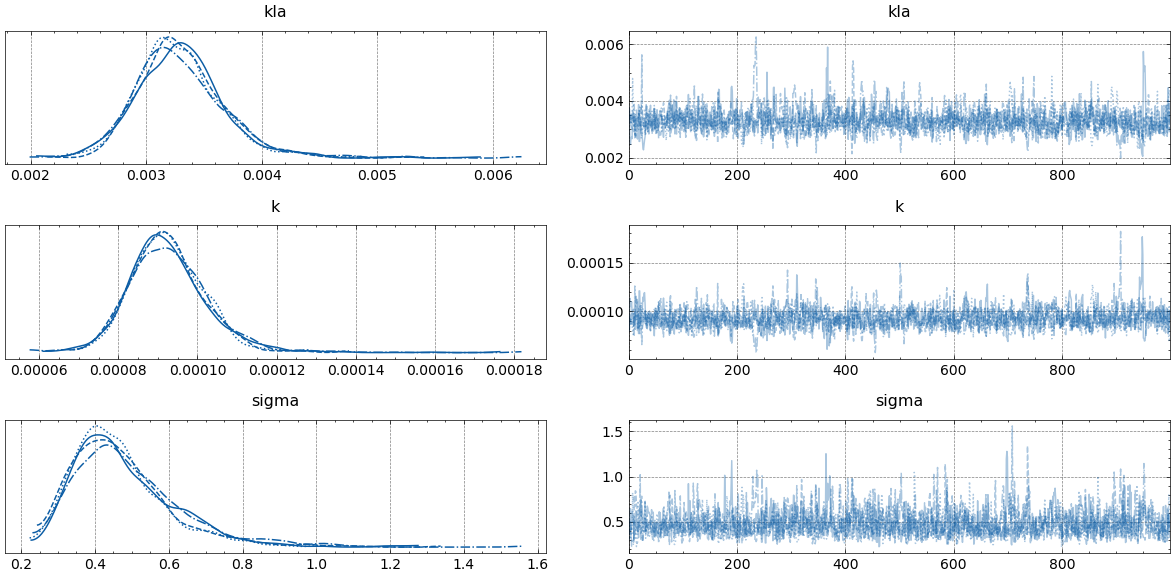

In [10]:
az.plot_trace(
    posterior_idata,
    var_names=[
        "kla",
        "k",
        "sigma",
    ],
)
plt.show()